In [1]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import torch
import open_clip
from PIL import Image

INPUT_DIR = Path("Places_Konkle_No_Humans") / Path('clip_rn50_results') / Path('selected_images')
OUTPUT_DIR = Path("Indoor_Outdoor_Images")
DATASETS = ["places", "konkle"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
BATCH_SIZE = 32

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"Using device: {DEVICE}")

MODEL_NAME = "RN50"
PRETRAINED = "openai"
model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model = model.to(DEVICE)
model.eval()
print("OpenCLIP RN50 loaded.")

INDOOR_PROMPTS = [
    "a photo of an indoor scene",
    "a photo taken inside a building",
    "an interior environment",
    "an indoor space",
    "a scene located inside a building or enclosed structure",
    "the interior of a room or building",
    "a photograph showing an interior space",
    "a scene primarily occurring indoors",
]

OUTDOOR_PROMPTS  = [
    "a photo of an outdoor scene",
    "a photo taken outside",
    "an exterior environment",
    "an outdoor space",
    "a scene located outside a building",
    "an open-air environment",
    "a photograph showing an exterior space",
    "a scene primarily occurring outdoors",
]

@torch.no_grad()
def encode_text_prompts(prompts):
    tokens = tokenizer(prompts).to(DEVICE)
    features = model.encode_text(tokens)
    features = features / features.norm(dim=-1, keepdim=True)
    return features
indoor_features = encode_text_prompts(INDOOR_PROMPTS)
outdoor_features = encode_text_prompts(OUTDOOR_PROMPTS)

def get_images(category_dir):
    return sorted([
        path for path in Path(category_dir).iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ])
    
def load_image(path):
    with Image.open(path) as img:
        return preprocess(img.convert("RGB"))
    
@torch.no_grad()
def classify_categorization_batch(image_paths):
    valid_paths = []
    tensors = []
    for path in image_paths:
        try:
            tensors.append(load_image(path))
            valid_paths.append(path)
        except Exception as e:
            print(f"Could not load {path}: {e}")
    if not tensors:
        return []
    images = torch.stack(tensors).to(DEVICE)
    image_features = model.encode_image(images)
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    indoor_similarity = image_features @ indoor_features.T
    outdoor_similarity = image_features @ outdoor_features.T
    indoor_score = indoor_similarity.mean(dim=1)
    outdoor_score = outdoor_similarity.mean(dim=1)
    results = []
    for path, in_s, out_s in zip(valid_paths, indoor_score.cpu().numpy(), outdoor_score.cpu().numpy()):
        confidence = abs(in_s - out_s)
        if confidence < 0.013:
            prediction = 'manual_review'
        elif in_s > out_s:
            prediction = "indoor"
        else:
            prediction = "outdoor"
        results.append({
                    "image_path": str(path),
                    "indoor_similarity": float(in_s),
                    "outdoor_similarity": float(out_s),
                    "prediction": prediction,
                    "confidence": confidence
                })
    return results

def categorize_dataset(dataset_name):
    source_dataset = INPUT_DIR / dataset_name
    destination_dataset = OUTPUT_DIR / dataset_name
    indoor_path = destination_dataset / Path("indoor")
    outdoor_path = destination_dataset / Path("outdoor")
    indoor_path.mkdir(parents=True, exist_ok=True)
    outdoor_path.mkdir(parents=True, exist_ok=True)
    
    if not source_dataset.exists():
        print(f"Dataset not found: {source_dataset}")
        return pd.DataFrame()
    category_dirs = sorted([
        path for path in source_dataset.iterdir()
        if path.is_dir()
    ])
    records = []
    print(f"\nCategorizing {dataset_name}: {len(category_dirs)} categories")
    
    for category_dir in category_dirs:
        
        category_records = []
        
        distinctive_dir = category_dir / "most_distinctive" # code added to also ensure category with <= 4 images
        least_distinctive_dir = category_dir / "least_distinctive"
        most_images = get_images(distinctive_dir) if distinctive_dir.exists() else []
        least_images = get_images(least_distinctive_dir) if least_distinctive_dir.exists() else []
        total_category_images = len(most_images) + len(least_images)
        if total_category_images <= 4:
            image_paths = most_images + least_images
        else:
            image_paths = most_images
        print(f"{dataset_name}/{category_dir.name}: {len(image_paths)} images")
        
        indoor_img = 0
        outdoor_img = 0
        manual_review_img = 0
        
        for start in range(0, len(image_paths), BATCH_SIZE):
            batch_paths = image_paths[start:start+BATCH_SIZE]
            batch_results = classify_categorization_batch(batch_paths)
            for result in batch_results:
                image_path = Path(result["image_path"])
                if result["prediction"] == "indoor":
                    indoor_img += 1
                elif result["prediction"] == "outdoor":
                    outdoor_img += 1
                else:
                    manual_review_img += 1
                category_records.append({
                        "dataset": dataset_name,
                        "category": category_dir.name,
                        "filename": image_path.name,
                        "image_path": str(image_path),
                        "indoor_similarity": result["indoor_similarity"],
                        "outdoor_similarity": result["outdoor_similarity"],
                        "prediction": result["prediction"],
                        "confidence": result["confidence"],
                    })
        
        total = indoor_img + outdoor_img + manual_review_img
        percentage_indoor = indoor_img / total * 100
        percentage_outdoor = outdoor_img / total * 100
        percentage_manual_review = manual_review_img / total * 100
        if percentage_indoor >= 80.0:
            category_prediction = "indoor"
            output_indoor = indoor_path / category_dir.name
            # shutil.copytree(distinctive_dir, output_indoor, dirs_exist_ok=True)
        elif percentage_outdoor >= 80.0:
            category_prediction = "outdoor"
            output_outdoor = outdoor_path / category_dir.name
            # shutil.copytree(distinctive_dir, output_outdoor, dirs_exist_ok=True)
        elif percentage_indoor > percentage_outdoor and percentage_indoor > percentage_manual_review:
            category_prediction = 'indoor'
            output_indoor = indoor_path / category_dir.name
        elif percentage_outdoor > percentage_indoor and percentage_outdoor > percentage_manual_review:
            category_prediction = 'outdoor'
            output_outdoor = outdoor_path / category_dir.name 
        else:
            category_prediction = 'manual_review'
            print(f"Warning: category {category_dir.name} requires further review")
        for record in category_records:
            record["category_prediction"] = category_prediction
            record["percentage_indoor"] = percentage_indoor
            record["percentage_outdoor"] = percentage_outdoor
            record["percentage_manual_review"] = percentage_manual_review
            if record['category_prediction'] == 'indoor' and record['prediction'] == 'indoor':
                output_indoor.mkdir(parents=True, exist_ok=True)
                shutil.copy2(record["image_path"], output_indoor / record["filename"])
            elif record['category_prediction'] == 'outdoor' and record['prediction'] == 'outdoor':
                output_outdoor.mkdir(parents=True, exist_ok=True)
                shutil.copy2(record["image_path"], output_outdoor / record["filename"])
        
        records.extend(category_records)
             
    return pd.DataFrame(records)

def run_categorization():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    frames = []
    for dataset in DATASETS:
        df = categorize_dataset(dataset)
        if not df.empty:
            frames.append(df)
    if frames:
        results = pd.concat(frames, ignore_index=True)
        results.to_csv(OUTPUT_DIR / "categorization_results.csv", index=False)
        print(f"\nCategorization results saved to {OUTPUT_DIR / 'categorization_results.csv'}")
        print(f"Indoor: {(results['prediction'] == 'indoor').sum()}")
        print(f"Outdoor: {(results['prediction'] == 'outdoor').sum()}")
        return results
    return pd.DataFrame()

if __name__ == "__main__":
    results = run_categorization()
                    

Using device: mps


/Users/3447783148qq.com/micromamba/envs/Lab_Project/lib/python3.13/site-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


OpenCLIP RN50 loaded.

Categorizing places: 201 categories
places/abbey-300: 30 images
places/airport_terminal-300: 25 images
places/alley-300: 30 images
places/amphitheater-300: 30 images
places/amusement_park-300: 30 images
places/apartment_building-300: 30 images
places/aquarium-300: 30 images
places/aqueduct-300: 30 images
places/arch-300: 30 images
places/art_gallery-300: 18 images
places/art_studio-300: 25 images
places/assembly_line-300: 30 images
places/attic-300: 30 images
places/auditorium-300: 30 images
places/badlands-300: 30 images
places/bakery-300: 30 images
places/ballroom-300: 17 images
places/bamboo_forest-300: 30 images
places/banquet_hall-300: 30 images
places/bar-300: 30 images
places/baseball_field-300: 7 images
places/basement-300: 30 images
places/basilica-300: 30 images
places/bayou-300: 30 images
places/beauty_salon-300: 30 images
places/bedroom-300: 30 images
places/boardwalk-300: 30 images
places/boat_deck-300: 30 images
places/bookstore-300: 30 images
place

['Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/alley-300/most_distinctive/gsun_95859e2be0997fc6d7c275d43b096e4b.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/laundromat-300/most_distinctive/gsun_8326424d17270e0e09ac6f777e181c37.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/iceberg-300/most_distinctive/gsun_7698f268d5a9c2db86bc24076a748335.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/vegetable_garden-300/most_distinctive/gsun_2676436c6b8bd859c7fe1c2de8b5dc16.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/auditorium-300/most_distinctive/gsun_f02ee1b07282a76b4aed933f56664f06.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/supermarket-300/most_distinctive/gsun_78ad135f6a9aa6c7257a831ef0ae273d.jpg', 'Places_Konkle_No_Humans/clip_rn50_results/selected_images/places/kindergarden_classroom-300/most_distinctive/gsun_5cc25a7126af7573f2d8fead53a30fab.

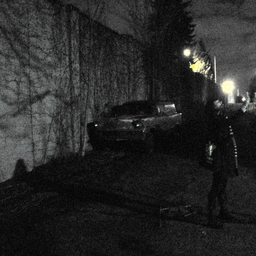

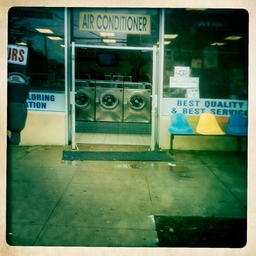

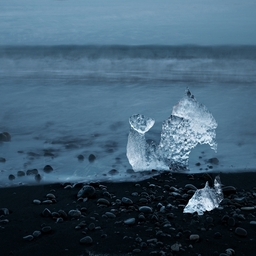

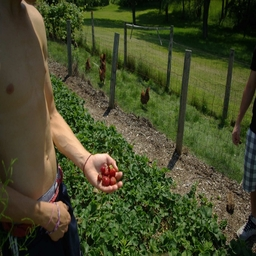

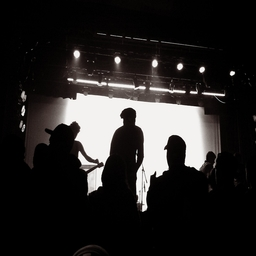

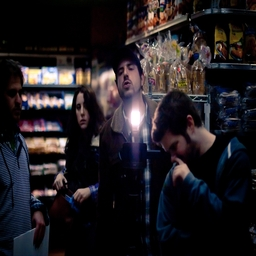

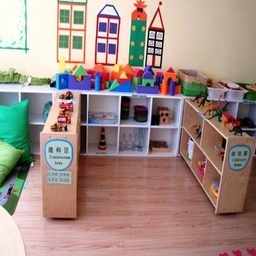

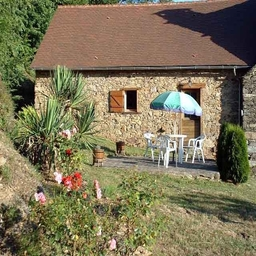

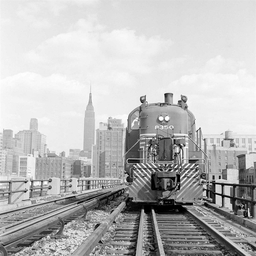

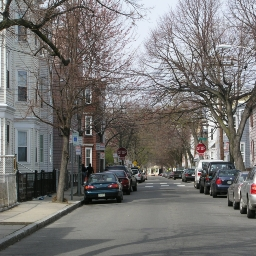

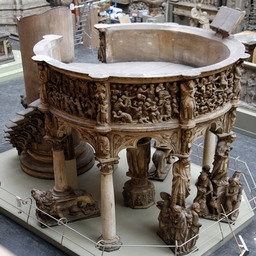

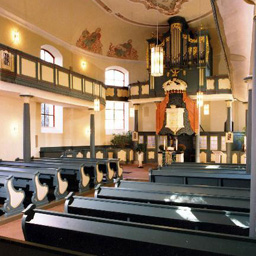

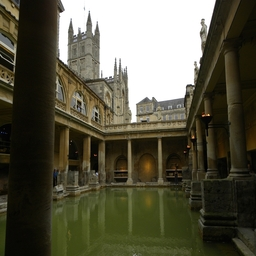

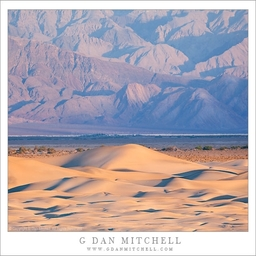

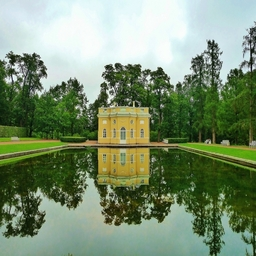

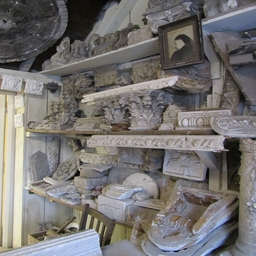

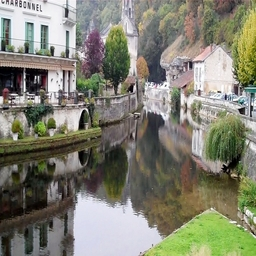

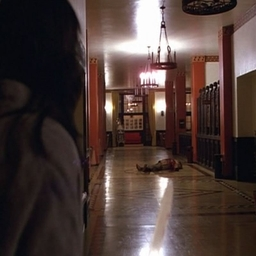

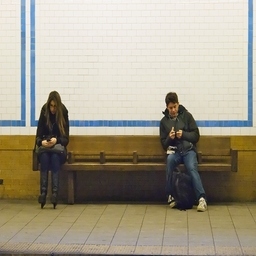

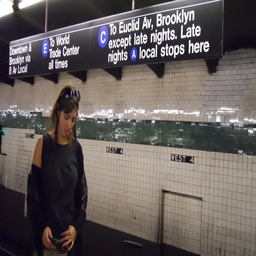

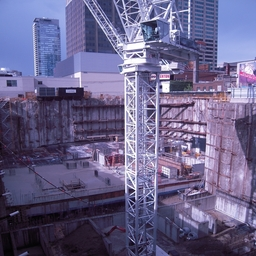

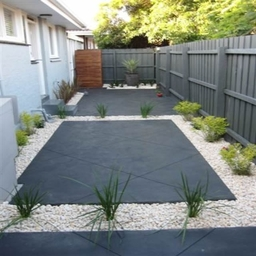

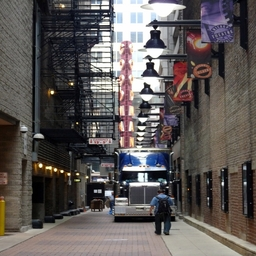

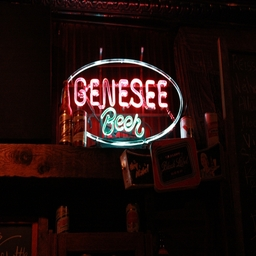

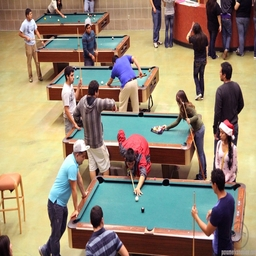

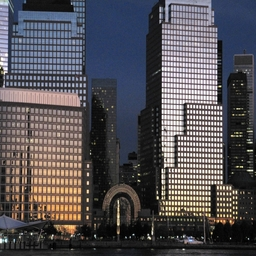

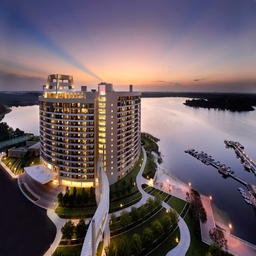

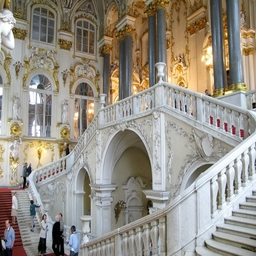

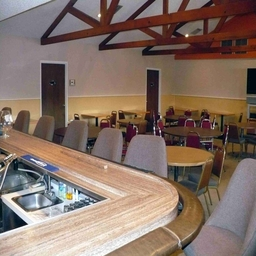

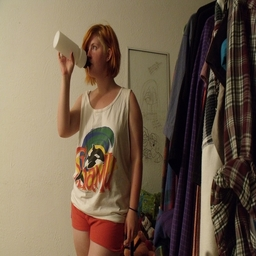

In [ ]:
from IPython.display import display, Image
import pandas as pd
import os
OUTPUT_DIR = Path("Indoor_Outdoor_Images")
df = pd.read_csv(OUTPUT_DIR / 'categorization_results.csv')
img_file = df.loc[:, 'image_path']
random_file = img_file.sample(n=30).tolist()
print(random_file)
for img in random_file:
    if os.path.exists(img):
        try:
            display(Image(filename=img))
        except Exception as e:
            print(f"Could not display image: {e}")

[{'dataset': 'places', 'category': 'cathedral-300', 'filename': 'outdoor_gsun_28b444be7f0fc13f271c32cd113788d1.jpg', 'image_path': 'Places_Konkle_Sample300/places/cathedral-300/outdoor_gsun_28b444be7f0fc13f271c32cd113788d1.jpg', 'num_detections': 0, 'max_detection_score': 0.0, 'strongest_label': nan, 'strongest_box': '[]', 'decision': 'kept'}, {'dataset': 'places', 'category': 'reception-300', 'filename': 'gsun_ff033a2ca05557ff1a3e0e77b30878b3.jpg', 'image_path': 'Places_Konkle_Sample300/places/reception-300/gsun_ff033a2ca05557ff1a3e0e77b30878b3.jpg', 'num_detections': 0, 'max_detection_score': 0.0, 'strongest_label': nan, 'strongest_box': '[]', 'decision': 'kept'}, {'dataset': 'places', 'category': 'hotel_room-300', 'filename': 'gsun_d2a6956c2d3ffc21828e5ca9fa572406.jpg', 'image_path': 'Places_Konkle_Sample300/places/hotel_room-300/gsun_d2a6956c2d3ffc21828e5ca9fa572406.jpg', 'num_detections': 0, 'max_detection_score': 0.0, 'strongest_label': nan, 'strongest_box': '[]', 'decision': 'ke

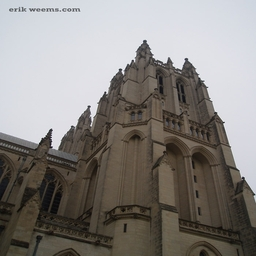

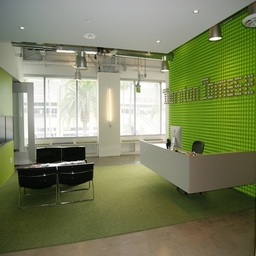

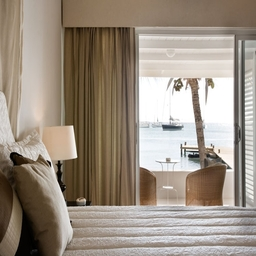

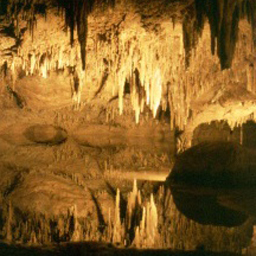

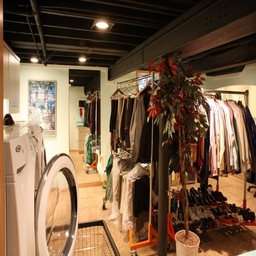

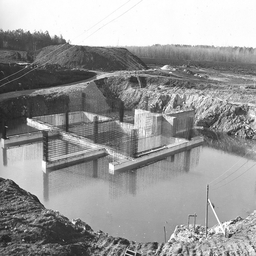

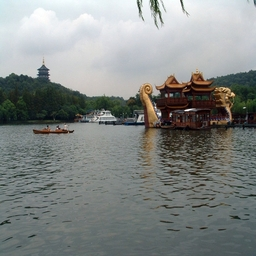

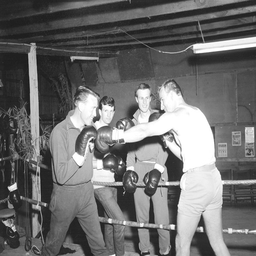

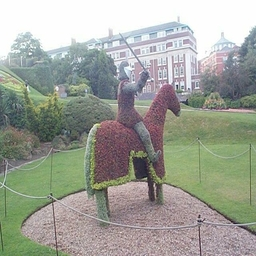

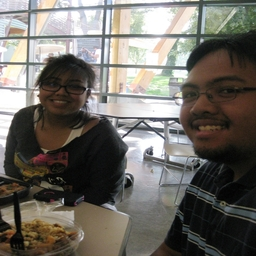

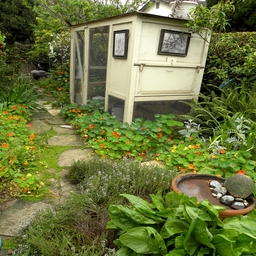

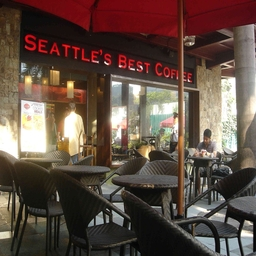

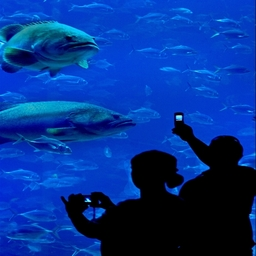

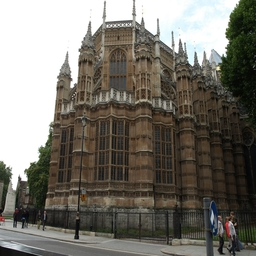

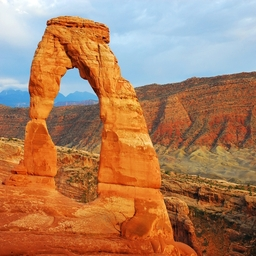

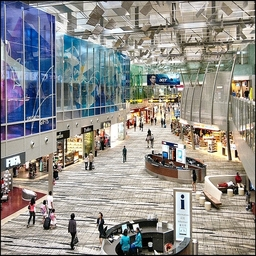

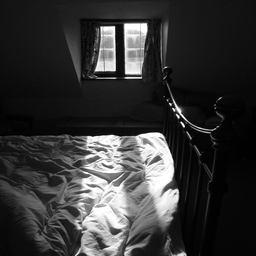

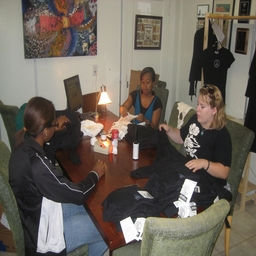

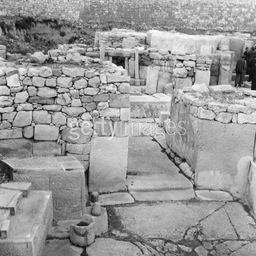

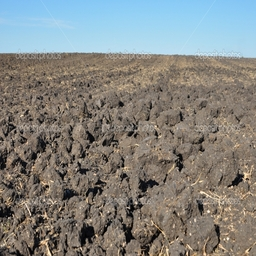

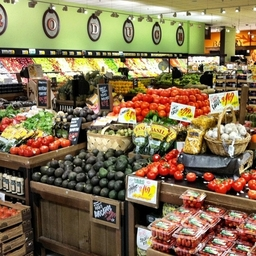

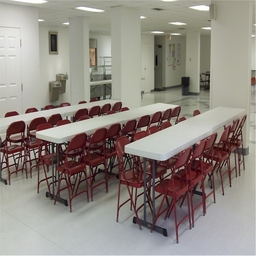

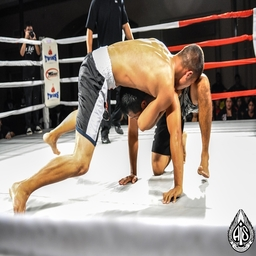

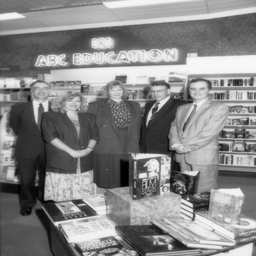

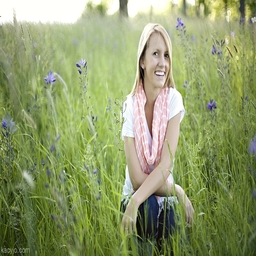

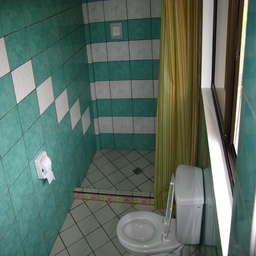

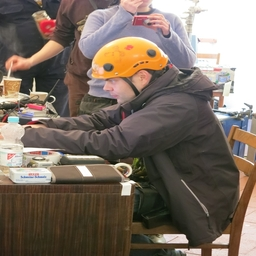

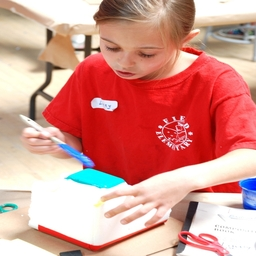

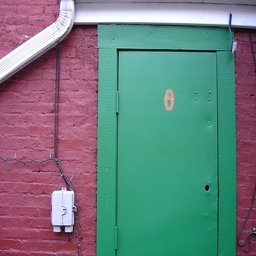

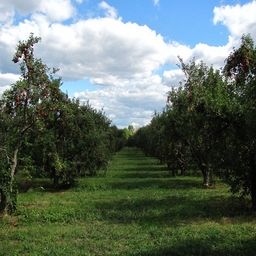

[['outdoor_gsun_28b444be7f0fc13f271c32cd113788d1.jpg', 'kept'], ['gsun_ff033a2ca05557ff1a3e0e77b30878b3.jpg', 'kept'], ['gsun_d2a6956c2d3ffc21828e5ca9fa572406.jpg', 'kept'], ['cavern-15.jpg', 'kept'], ['gsun_d6f1c06aa3fe2ec624b50ea8b4323ce1.jpg', 'excluded'], ['gsun_c90827d25633a965f10b9b4d2e1911ac.jpg', 'kept'], ['outdoor_gsun_4228c6d6971fec5ded3becae2d0ec738.jpg', 'excluded'], ['gsun_7427557ea7ce4d5922d5dc7669886d0f.jpg', 'excluded'], ['gsun_ea78154363801d60be15c2e83fa06ea1.jpg', 'excluded'], ['gsun_6259905f51e6dc58f93ec1eaee25da8b.jpg', 'excluded'], ['gsun_4dedad038b863f1b9bb801a9d708c468.jpg', 'kept'], ['gsun_d25ecc179657940885e52284cfce8620.jpg', 'excluded'], ['gsun_5ecec9783d85c605afe01deb532ad2d2.jpg', 'excluded'], ['gsun_d1043bc0d9c67f53a6b98b8479c00e0d.jpg', 'excluded'], ['gsun_dc953f6fa986659803591f827b8a5ab2.jpg', 'kept'], ['gsun_eb9a7f8ed795bada130107ab19f6a6fc.jpg', 'excluded'], ['gsun_197674e81dc5e573e7a796913e94c128.jpg', 'kept'], ['gsun_b5620bbcd4baf214ff70f26dd4af5bc5.

In [ ]:
from IPython.display import display, Image
import pandas as pd
import os
INPUT_DIR = Path("Places_Konkle_No_Humans") 
df = pd.read_csv(INPUT_DIR / 'human_filter_results.csv')
random_file = df.sample(n=30).to_dict(orient="records")
print(random_file)
result = []
for row in random_file:
    if os.path.exists(row["image_path"]):
        try:
            result.append([row["filename"], row["decision"]])
            display(Image(row["image_path"]))
        except Exception as e:
            print(f"Could not display image: {e}")
print(result)

In [4]:
from pathlib import Path
import shutil
import pandas as pd
import random

CSV_PATH = Path("Indoor_Outdoor_Images") / "categorization_results.csv"
OUTPUT_DIR = Path("Random_2200_Images")
N_PER_GROUP = 1100
RANDOM_SEED = 42

df = pd.read_csv(CSV_PATH)

indoor_df = df[df["prediction"] == "indoor"]
outdoor_df = df[df["prediction"] == "outdoor"]

print(f"Available indoor images: {len(indoor_df)}")
print(f"Available outdoor images: {len(outdoor_df)}")

n_indoor = min(N_PER_GROUP, len(indoor_df))
n_outdoor = min(N_PER_GROUP, len(outdoor_df))

# indoor_sample = indoor_df.sample(n=n_indoor, random_state=RANDOM_SEED)
# outdoor_sample = outdoor_df.sample(n=n_outdoor, random_state=RANDOM_SEED)

indoor_exclude = [
    "insidecar", "planeinside",                          # konkle
    "bus_interior-300", "cockpit-300", "galley-300", "engine_room-300",  # places
]

outdoor_exclude = [
    "train",                                             # konkle
    "raft-300", "boat_deck-300", "phone_booth-300", "sky-300",  # places
]

indoor_category_df = df[(df['category_prediction'] == 'indoor') & (~df['category'].isin(indoor_exclude))]
outdoor_category_df = df[(df['category_prediction'] == 'outdoor') & (~df['category'].isin(outdoor_exclude))]

selected = indoor_category_df + outdoor_category_df

print(selected['category'].isin(indoor_exclude + outdoor_exclude).any())

indoor_output = OUTPUT_DIR / "indoor"
outdoor_output = OUTPUT_DIR / "outdoor"
indoor_output.mkdir(parents=True, exist_ok=True)
outdoor_output.mkdir(parents=True, exist_ok=True)

def copy_sample_by_category(sample_df, destination):
    rng = random.Random(RANDOM_SEED)
    allowed_count = 0
    
    if sample_df is indoor_category_df:
        condition = 'indoor'
    else:
        condition = 'outdoor'
    row_list = sample_df[sample_df['prediction'] == condition].to_dict('records')
    
    result = [] # get a list of all category names in this sample_df, each item being a sublist containing all images \
        # for that category
    seen_categories = set()
    for row in row_list:
        category = (row['dataset'], row['category'])
        if category not in seen_categories:
            seen_categories.add(category)
            result.append([row for row in row_list if (row['dataset'], row['category']) == category])
    
    rng.shuffle(result)
    
    record = [] # keep track of the selected images
    while allowed_count < min(N_PER_GROUP, len(row_list)):
        for category in result: # for each category, randomly select one image
            if not category:
                continue
            img = rng.choice(category)
            category.remove(img)
            record.append(img)
            source = Path(img["image_path"])
            new_name = f"{img['dataset']}_{img['category']}_{img['filename']}"
            shutil.copy2(source, destination / new_name)
            allowed_count += 1
            if allowed_count >= min(N_PER_GROUP, len(row_list)):
                break
    return pd.DataFrame(record)
            

record1 = copy_sample_by_category(indoor_category_df, indoor_output)
record2 = copy_sample_by_category(outdoor_category_df, outdoor_output)

selected = pd.concat([record1, record2], ignore_index=True)

selected.to_csv(OUTPUT_DIR / "random_2200_images.csv", index=False)

print(f"\nCopied {len(record1)} indoor images to: {indoor_output}")
print(f"Copied {len(record2)} outdoor images to: {outdoor_output}")
print(f"Selection CSV saved to: {OUTPUT_DIR / 'random_2000_images.csv'}")

Available indoor images: 1598
Available outdoor images: 3337
False

Copied 1100 indoor images to: Random_2200_Images/indoor
Copied 1100 outdoor images to: Random_2200_Images/outdoor
Selection CSV saved to: Random_2200_Images/random_2000_images.csv


In [5]:
from pathlib import Path
import shutil
import pandas as pd
import random

CSV_PATH = Path("Indoor_Outdoor_Images") / "categorization_results.csv"
OUTPUT_DIR = Path("Random_1400_Images")
N_PER_GROUP = 700
RANDOM_SEED = 30

df = pd.read_csv(CSV_PATH)

indoor_df = df[df["prediction"] == "indoor"]
outdoor_df = df[df["prediction"] == "outdoor"]

print(f"Available indoor images: {len(indoor_df)}")
print(f"Available outdoor images: {len(outdoor_df)}")

n_indoor = min(N_PER_GROUP, len(indoor_df))
n_outdoor = min(N_PER_GROUP, len(outdoor_df))

# indoor_sample = indoor_df.sample(n=n_indoor, random_state=RANDOM_SEED)
# outdoor_sample = outdoor_df.sample(n=n_outdoor, random_state=RANDOM_SEED)

indoor_exclude = [
    "insidecar", "planeinside",                          # konkle
    "bus_interior-300", "cockpit-300", "galley-300", "engine_room-300",  # places
]

outdoor_exclude = [
    "train",                                             # konkle
    "raft-300", "boat_deck-300", "phone_booth-300", "sky-300",  # places
]

indoor_category_df = df[(df['category_prediction'] == 'indoor') & (~df['category'].isin(indoor_exclude))]
outdoor_category_df = df[(df['category_prediction'] == 'outdoor') & (~df['category'].isin(outdoor_exclude))]

selected = indoor_category_df + outdoor_category_df

print(selected['category'].isin(indoor_exclude + outdoor_exclude).any())

indoor_output = OUTPUT_DIR / "indoor"
outdoor_output = OUTPUT_DIR / "outdoor"
indoor_output.mkdir(parents=True, exist_ok=True)
outdoor_output.mkdir(parents=True, exist_ok=True)

def copy_sample_by_category(sample_df, destination):
    rng = random.Random(RANDOM_SEED)
    allowed_count = 0
    
    if sample_df is indoor_category_df:
        condition = 'indoor'
    else:
        condition = 'outdoor'
    row_list = sample_df[sample_df['prediction'] == condition].to_dict('records')
    
    result = [] # get a list of all category names in this sample_df, each item being a sublist containing all images \
        # for that category
    seen_categories = set()
    for row in row_list:
        category = (row['dataset'], row['category'])
        if category not in seen_categories:
            seen_categories.add(category)
            result.append([row for row in row_list if (row['dataset'], row['category']) == category])
    
    rng.shuffle(result)
    
    record = [] # keep track of the selected images
    while allowed_count < min(N_PER_GROUP, len(row_list)):
        for category in result: # for each category, randomly select one image
            if not category:
                continue
            img = rng.choice(category)
            category.remove(img)
            record.append(img)
            source = Path(img["image_path"])
            new_name = f"{img['dataset']}_{img['category']}_{img['filename']}"
            shutil.copy2(source, destination / new_name)
            allowed_count += 1
            if allowed_count >= min(N_PER_GROUP, len(row_list)):
                break
    return pd.DataFrame(record)
            

record1 = copy_sample_by_category(indoor_category_df, indoor_output)
record2 = copy_sample_by_category(outdoor_category_df, outdoor_output)

selected = pd.concat([record1, record2], ignore_index=True)

selected.to_csv(OUTPUT_DIR / "random_1400_images.csv", index=False)

print(f"\nCopied {len(record1)} indoor images to: {indoor_output}")
print(f"Copied {len(record2)} outdoor images to: {outdoor_output}")
print(f"Selection CSV saved to: {OUTPUT_DIR / 'random_2000_images.csv'}")

Available indoor images: 1598
Available outdoor images: 3337
False

Copied 700 indoor images to: Random_1400_Images/indoor
Copied 700 outdoor images to: Random_1400_Images/outdoor
Selection CSV saved to: Random_1400_Images/random_2000_images.csv


In [1]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

IMAGE_DIR = Path("Indoor_Outdoor_Images")
OUTPUT_CSV = "image_pixel_features.csv"

results = []

for path in sorted(IMAGE_DIR.rglob("*")):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    with Image.open(path) as image:
        rgb = np.asarray(
            image.convert("RGB").resize((306, 306)),
            dtype=np.float64
        ) / 255.0

    # Convert image to grayscale
    gray = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    # 1. Mean luminance (approximate)
    luminance = gray.mean()

    # 2. RMS contrast
    contrast = gray.std()

    # 3. Mean edge strength
    gy, gx = np.gradient(gray)
    edge_strength = np.sqrt(gx**2 + gy**2).mean()

    # 4. Grayscale entropy
    histogram, _ = np.histogram(
        gray, bins=32, range=(0, 1)
    )
    probabilities = histogram / histogram.sum()
    probabilities = probabilities[probabilities > 0]
    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    results.append({
        "image_path": str(path),
        "luminance": luminance,
        "contrast": contrast,
        "edge_strength": edge_strength,
        "entropy": entropy
    })

df = pd.DataFrame(results)
df.to_csv(OUTPUT_CSV, index=False)

print(df.describe())


         luminance     contrast  edge_strength      entropy
count  4462.000000  4462.000000    4462.000000  4462.000000
mean      0.461742     0.223797       0.039237     4.374722
std       0.115893     0.055314       0.016753     0.397850
min       0.028832     0.041848       0.003821     1.459220
25%       0.395877     0.185896       0.027205     4.204180
50%       0.471443     0.223273       0.036886     4.466743
75%       0.535401     0.261228       0.048441     4.649992
max       0.932654     0.444162       0.135576     4.969760


In [1]:

import os
import glob
import torch
import pandas as pd
from PIL import Image
from resmem import ResMem, transformer
from falseresmem import predict_image

# 1. Select device
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print(f"Using device: {DEVICE}")

# 2. Load ResMem
resmem_model = ResMem(pretrained=True).to(DEVICE)
resmem_model.eval()

# 3. Define target folders
folders_to_process = {
    "Indoor_Set": "/Users/3447783148qq.com/Desktop/Random_2200_Images/indoor_merged_1000",
    "Outdoor_Set": "/Users/3447783148qq.com/Desktop/Random_2200_Images/outdoor_merged_1000"
}

BATCH_SIZE = 32
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
all_results = []

def load_image(path):
    with Image.open(path) as img:
        return transformer(img.convert("RGB"))

# 4. Process images
for folder_tag, folder_path in folders_to_process.items():
    print(f"\nProcessing {folder_tag}: {folder_path}")

    image_paths = sorted(
        path
        for path in glob.glob(
            os.path.join(folder_path, "**", "*"),
            recursive=True
        )
        if os.path.isfile(path)
        and path.lower().endswith(IMAGE_EXTENSIONS)
    )

    print(f"Found {len(image_paths)} images")

    for start in range(0, len(image_paths), BATCH_SIZE):
        batch_paths = image_paths[start:start + BATCH_SIZE]
        valid_batch_paths = []
        batch_tensors = []

        for img_path in batch_paths:
            try:
                batch_tensors.append(load_image(img_path))
                valid_batch_paths.append(img_path)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

        if not batch_tensors:
            continue

        # Convert list of image tensors into a batch
        batch = torch.stack(batch_tensors).to(DEVICE)

        # ResMem predictions
        with torch.inference_mode():
            resmem_scores = (
                resmem_model(batch)
                .reshape(-1)
                .cpu()
                .tolist()
            )

        if len(resmem_scores) != len(valid_batch_paths):
            raise ValueError("ResMem prediction count mismatch")

        # Save one result per image
        for img_path, resmem_score in zip(
            valid_batch_paths, resmem_scores
        ):
            try:
                # FalseResMem's official image-level API
                falseresmem_score = float(
                    predict_image(img_path).item()
                )
            except Exception as e:
                print(f"FalseResMem error for {img_path}: {e}")
                falseresmem_score = float("nan")

            all_results.append({
                "Folder": folder_tag,
                "image_path": img_path,
                "filename": os.path.basename(img_path),
                "ResMem_Score": resmem_score,
                "FalseResMem_Score": falseresmem_score
            })

        print(
            f"Completed {min(start + BATCH_SIZE, len(image_paths))}"
            f"/{len(image_paths)}"
        )

# 5. Save results
df = pd.DataFrame(
    all_results,
    columns=[
        "Folder",
        "image_path",
        "filename",
        "ResMem_Score",
        "FalseResMem_Score"
    ]
)

df.to_csv("memorability_scores.csv", index=False)

print("\nProcessing complete!")
print(f"Total images processed: {len(df)}")
print(f"Missing FalseResMem scores: {df['FalseResMem_Score'].isna().sum()}")
print("Saved to memorability_scores.csv")


Using device: mps


/Users/3447783148qq.com/micromamba/envs/Lab_Project/lib/python3.13/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/3447783148qq.com/micromamba/envs/Lab_Project/lib/python3.13/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Processing Indoor_Set: /Users/3447783148qq.com/Desktop/Random_2200_Images/indoor_merged_1000
Found 1000 images
Completed 32/1000
Completed 64/1000
Completed 96/1000
Completed 128/1000
Completed 160/1000
Completed 192/1000
Completed 224/1000
Completed 256/1000
Completed 288/1000
Completed 320/1000
Completed 352/1000
Completed 384/1000
Completed 416/1000
Completed 448/1000
Completed 480/1000
Completed 512/1000
Completed 544/1000
Completed 576/1000
Completed 608/1000
Completed 640/1000
Completed 672/1000
Completed 704/1000
Completed 736/1000
Completed 768/1000
Completed 800/1000
Completed 832/1000
Completed 864/1000
Completed 896/1000
Completed 928/1000
Completed 960/1000
Completed 992/1000
Completed 1000/1000

Processing Outdoor_Set: /Users/3447783148qq.com/Desktop/Random_2200_Images/outdoor_merged_1000
Found 1000 images
Completed 32/1000
Completed 64/1000
Completed 96/1000
Completed 128/1000
Completed 160/1000
Completed 192/1000
Completed 224/1000
Completed 256/1000
Completed 288/1000


In [4]:
from pathlib import Path
import shutil
import pandas as pd
import random
import numpy as np                      # NEW (for the image filter)
from PIL import Image                   # NEW (for the image filter)

CSV_PATH = Path("Indoor_Outdoor_Images") / "categorization_results.csv"
OUTPUT_DIR = Path("Random_720_Images")                      # CHANGED (was Random_1400_Images)
N_PER_GROUP = 360                                           # CHANGED (was 700)
RANDOM_SEED = 30

RAND_DIR = Path.home() / "Desktop" / "Random_2200_Images"

USED_CSVS = [
    RAND_DIR / "random_2200_images.csv",
    RAND_DIR / "merged_indoor_outdoor_1000_each.csv",
    RAND_DIR / "excluded_images.csv",
]


# ===========================================================================
# NEW FUNCTIONS (everything below the next line of "=" is your original code)
# ===========================================================================
def passes_auto_filters(path):
    try:
        im = Image.open(path)
        w, h = im.size
        if not 0.9 <= w / h <= 1.1:                      # peculiar shape
            return False
        a = np.asarray(im.convert("RGB")).astype(int)
    except Exception as e:                               # unreadable file
        print(f"could not open {path}: {e}")
        return False
    if (np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) < 6:   # black/white
        return False
    for k in (3, 6):                                     # uniform border => frame
        strips = [a[:k], a[-k:], a[:, :k], a[:, -k:]]
        if sum(s.std() < 8 for s in strips) >= 3:
            return False
    return True


def remove_used_images(data):
    """Drops rows whose image is listed in any of the USED_CSVS."""
    names = (data["dataset"].astype(str) + "_" + data["category"].astype(str)
             + "_" + data["filename"].astype(str)).str.lower()
    master_names = set(names)
    used_names = set()
    for csv_file in USED_CSVS:
        d = pd.read_csv(csv_file)
        keys = []                                        # whichever naming columns the CSV has
        if "new_name" in d.columns:
            keys.append(d["new_name"].astype(str).str.lower())
        if {"dataset", "category", "filename"} <= set(d.columns):
            keys.append((d["dataset"].astype(str) + "_" + d["category"].astype(str)
                         + "_" + d["filename"].astype(str)).str.lower())
        if "image_path" in d.columns:
            keys.append(d["image_path"].astype(str).map(lambda p: Path(p).name.lower()))
        if not keys:
            raise ValueError(f"{csv_file}: no usable columns, found {list(d.columns)}")
        hit = pd.Series(False, index=d.index)
        for k in keys:
            hit |= k.isin(master_names)
            used_names |= set(k)
        print(f"{csv_file}: {len(d)} rows, {hit.sum()} matched to the master CSV")
        if hit.sum() < len(d):
            print(f"  WARNING: {len(d) - hit.sum()} rows not matched - those images may not be excluded")
    kept = data[~names.isin(used_names)]
    print(f"Removed {len(data) - len(kept)} already-used images")
    return kept


def filter_images(data, label):
    """Keeps only rows whose image passes passes_auto_filters (can take a few minutes)."""
    keep = []
    for i, p in enumerate(data["image_path"], 1):
        keep.append(passes_auto_filters(p))
        if i % 2000 == 0:
            print(f"  {label}: checked {i}/{len(data)} images")
    kept = data[pd.Series(keep, index=data.index)]
    print(f"{label}: {len(kept)} of {len(data)} images pass the image filter")
    return kept
# ===========================================================================


df = pd.read_csv(CSV_PATH)
df = remove_used_images(df)                                 # NEW

indoor_df = df[df["prediction"] == "indoor"]
outdoor_df = df[df["prediction"] == "outdoor"]

print(f"Available indoor images: {len(indoor_df)}")
print(f"Available outdoor images: {len(outdoor_df)}")

n_indoor = min(N_PER_GROUP, len(indoor_df))
n_outdoor = min(N_PER_GROUP, len(outdoor_df))

# indoor_sample = indoor_df.sample(n=n_indoor, random_state=RANDOM_SEED)
# outdoor_sample = outdoor_df.sample(n=n_outdoor, random_state=RANDOM_SEED)

indoor_exclude = [
    "insidecar", "planeinside",                          # konkle
    "bus_interior-300", "cockpit-300", "galley-300", "engine_room-300",  # places
]

outdoor_exclude = [
    "train",                                             # konkle
    "raft-300", "boat_deck-300", "phone_booth-300", "sky-300",  # places
]

indoor_category_df = df[(df['category_prediction'] == 'indoor') & (~df['category'].isin(indoor_exclude))]
outdoor_category_df = df[(df['category_prediction'] == 'outdoor') & (~df['category'].isin(outdoor_exclude))]

indoor_category_df = filter_images(indoor_category_df, "indoor")      # NEW
outdoor_category_df = filter_images(outdoor_category_df, "outdoor")   # NEW

selected = indoor_category_df + outdoor_category_df

print(selected['category'].isin(indoor_exclude + outdoor_exclude).any())

indoor_output = OUTPUT_DIR / "indoor"
outdoor_output = OUTPUT_DIR / "outdoor"
indoor_output.mkdir(parents=True, exist_ok=True)
outdoor_output.mkdir(parents=True, exist_ok=True)

def copy_sample_by_category(sample_df, destination):
    rng = random.Random(RANDOM_SEED)
    allowed_count = 0
    
    if sample_df is indoor_category_df:
        condition = 'indoor'
    else:
        condition = 'outdoor'
    if condition == 'indoor':                                      # CHANGED
        row_list = sample_df.to_dict('records')
    else:
        row_list = sample_df[sample_df['prediction'] == condition].to_dict('records')
    
    result = [] # get a list of all category names in this sample_df, each item being a sublist containing all images \
        # for that category
    seen_categories = set()
    for row in row_list:
        category = (row['dataset'], row['category'])
        if category not in seen_categories:
            seen_categories.add(category)
            result.append([row for row in row_list if (row['dataset'], row['category']) == category])
    
    rng.shuffle(result)
    
    record = [] # keep track of the selected images
    while allowed_count < min(N_PER_GROUP, len(row_list)):
        for category in result: # for each category, randomly select one image
            if not category:
                continue
            img = rng.choice(category)
            category.remove(img)
            record.append(img)
            source = Path(img["image_path"])
            new_name = f"{img['dataset']}_{img['category']}_{img['filename']}"
            shutil.copy2(source, destination / new_name)
            allowed_count += 1
            if allowed_count >= min(N_PER_GROUP, len(row_list)):
                break
    return pd.DataFrame(record)
            

record1 = copy_sample_by_category(indoor_category_df, indoor_output)
record2 = copy_sample_by_category(outdoor_category_df, outdoor_output)

selected = pd.concat([record1, record2], ignore_index=True)

selected.to_csv(OUTPUT_DIR / "random_1400_images.csv", index=False)

print(f"\nCopied {len(record1)} indoor images to: {indoor_output}")
print(f"Copied {len(record2)} outdoor images to: {outdoor_output}")
print(f"Selection CSV saved to: {OUTPUT_DIR / 'random_2000_images.csv'}")


/Users/3447783148qq.com/Desktop/Random_2200_Images/random_2200_images.csv: 2200 rows, 2200 matched to the master CSV
/Users/3447783148qq.com/Desktop/Random_2200_Images/merged_indoor_outdoor_1000_each.csv: 2000 rows, 1913 matched to the master CSV
/Users/3447783148qq.com/Desktop/Random_2200_Images/excluded_images.csv: 404 rows, 404 matched to the master CSV
Removed 2400 already-used images
Available indoor images: 376
Available outdoor images: 2159
indoor: 341 of 362 images pass the image filter
  outdoor: checked 2000/2690 images
outdoor: 2492 of 2690 images pass the image filter
False

Copied 341 indoor images to: Random_720_Images/indoor
Copied 360 outdoor images to: Random_720_Images/outdoor
Selection CSV saved to: Random_720_Images/random_2000_images.csv
